<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/01-eda-room-occupancy/eda_room_occupancy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Exploratory Analysis (EDA) — це початковий процес дослідження та аналізу набору даних для розуміння його структури, змісту та виявлення важливих характеристик перед проведенням моделювання.

Exploratory Data Analysis допомагає отримати загальне розуміння даних, виявити проблеми з якістю даних та підготувати набір даних для подальшого моделювання.

**Важливі інструменти:**
- **pandas** для роботи з даними у вигляді DataFrame,
- **seaborn**, **matplotlib** для візуалізаці,
- **numpy** для роботи з числовими матрицями.


Основні етапи EDA включають:

1. **Збір та завантаження даних**
   - Перший етап полягає в отриманні набору даних, що може включати завантаження з джерел, як-от бази даних, CSV-файли, веб-ресурси, API тощо.
   - Перевірка розміру та структури набору даних (кількість рядків, стовпців).
   
    **Інструменти**: `pandas`, `requests`.

2. **Первинна перевірка даних**
   - Перегляд кількох перших і останніх рядків даних (`head()`, `tail()`).
   - Описова статистика для числових змінних, наприклад, середнє, медіана, мода, мінімум, максимум, стандартне відхилення (`describe()`).
   - Перевірка типів даних кожної змінної (`dtypes`).
   
    **Інструменти**: `pandas`.

3. **Обробка пропущених даних та дублікатів**
   - Виявлення відсутніх або некоректних значень (`isnull()`, `notnull()`).
   - Прийняття рішень щодо обробки: видалення рядків або стовпців із пропущеними даними, заповнення пропущених значень середнім, медіаною або інтерполяцією.
   
    **Інструменти**: `pandas`, `numpy`.

4. **Аналіз та очищення аномалій**
   - Пошук аномалій (outliers), тобто значень, що значно відрізняються від решти даних.
   - Візуалізація за допомогою діаграм розмаху (box plot) або гістограм.
   - Прийняття рішень щодо того, чи видаляти аномалії або враховувати їх.

    **Інструменти**: `seaborn`, `matplotlib`.

5. **Аналіз розподілу змінних**
   - Побудова гістограм і діаграм розмаху для оцінки розподілу змінних.
   - Оцінка, чи змінні мають нормальний розподіл, чи розподіл є зміщеним.
   
    **Інструменти**: `seaborn`, `matplotlib`.

6. **Аналіз кореляцій між змінними**
   - Обчислення кореляційної матриці для числових змінних (`corr()`), щоб зрозуміти, як одна змінна залежить від іншої.
   - Візуалізація кореляцій за допомогою теплових карт (heatmap).
   
    **Інструменти**: `pandas`, `seaborn`.

7. **Категоріальний аналіз**
   - Аналіз категоріальних змінних: частотний розподіл, діаграми частот (bar plot), відсоткове співвідношення.
   - Оцінка унікальних значень і їх розподілу.
   
    **Інструменти**: `pandas`, `seaborn`.

8. **Аналіз залежності між змінними**
   - Візуалізація залежностей між змінними (scatter plot, pair plot).
   - Аналіз взаємодії між незалежними змінними і цільовою змінною.
   
    **Інструменти**: `seaborn`, `matplotlib`.

9. **Агрегація та групування даних**
   - Групування даних за категоріями або часовими рамками, обчислення середніх, медіан або інших агрегованих показників для певних підмножин даних.
   
    **Інструменти**: `groupby()` з `pandas`.

10. **Висновки та гіпотези**
   - Формування попередніх гіпотез на основі аналізу даних.
   - Виявлення важливих трендів, взаємозв’язків та особливостей даних.

11. **Підготовка даних до моделювання**
   - Очищення даних від пропусків та аномалій.
   - Трансформація змінних: нормалізація, стандартизація, кодування категоріальних змінних (one-hot encoding).
   - Розділення даних на тренувальні і тестові вибірки.


Додаткові матеріали:

https://medium.com/@pabbakavya123/a-comprehensive-guide-on-exploratory-data-analysis-eda-ab38f33d6abc

https://www.geeksforgeeks.org/steps-for-mastering-exploratory-data-analysis-eda-steps/

https://www.kdnuggets.com/7-steps-to-mastering-exploratory-data-analysis









Для виконання лабораторної роботи необхідно виконати такі дії:


#1.Збір та завантаження даних

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
import time
import pickle

from scipy.stats import normaltest


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

Date: YYYY/MM/DD

Time: HH:MM:SS

Temperature: In degree Celsius

Light: In Lux

Sound: In Volts (amplifier output read by ADC)

CO2: In PPM

CO2 Slope: Slope of CO2 values taken in a sliding window

PIR: Binary value conveying motion detection

Room_Occupancy_Count: Ground Truth

Опис датасету зайнятості приміщення

Умови експерименту: кімната розміром 6 × 4,6 м без використання систем вентиляції та клімат-контролю (HVAC). Збір тривав 4 дні, зайнятість варіювалася від 0 до 3 людей (еталонні дані фіксувалися вручну).

Мережева архітектура: топологія «зірка» з 7 сенсорних вузлів та 1 граничного вузла (edge node). Дані передавалися бездротово кожні 30 секунд.

Сенсори S1–S4 (температура, світло, звук): датчик звуку на основі мікрофона передає аналоговий сигнал на АЦП мікроконтролера у вольтах; потенціометр налаштовано на максимальну чутливість.

Сенсор S5 (вуглекислий газ, CO2): потребував ручного калібрування нульової точки — 20 хвилин у чистому середовищі та утримання піна HD у низькому стані понад 7 секунд.

Сенсори S6–S7 (пасивні інфрачервоні, PIR): розміщені під стелею під кутом для максимального охоплення руху; тримери чутливості й тривалості активного сигналу викручені на максимум.

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
room_occupancy_estimation = fetch_ucirepo(id=864) #Room Occupancy Estimation

# data (as pandas dataframes)
X = room_occupancy_estimation.data.features
y = room_occupancy_estimation.data.targets

#x-input data
#y-definitive answer we are training our model to predict

# metadata
print(f"Metadata: {room_occupancy_estimation.metadata}")

# variable information
print(f"\n\n\nVariables: {room_occupancy_estimation.variables}")


Metadata: {'uci_id': 864, 'name': 'Room Occupancy Estimation', 'repository_url': 'https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation', 'data_url': 'https://archive.ics.uci.edu/static/public/864/data.csv', 'abstract': 'Data set for estimating the precise number of occupants in a room using multiple non-intrusive environmental sensors like temperature, light, sound, CO2 and PIR.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 10129, 'num_features': 18, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Room_Occupancy_Count'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Wed Aug 16 2023', 'dataset_doi': '10.24432/C5P605', 'creators': ['Adarsh Pal Singh', 'Sachin Chaudhari'], 'intro_paper': {'ID': 275, 'type': 'NATIVE', 'title': 'Machine Learning-Based Occupancy Estimation Using Multivariate Sensor Nod

#2.Первинна перевірка даних

In [ ]:
X
#s - sensor nodes

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10124,2018/01/11,08:58:07,25.06,25.13,24.69,25.31,6,7,33,22,0.09,0.04,0.06,0.08,345,0.000000,0,0
10125,2018/01/11,08:58:37,25.06,25.06,24.69,25.25,6,7,34,22,0.07,0.05,0.05,0.08,345,0.000000,0,0
10126,2018/01/11,08:59:08,25.13,25.06,24.69,25.25,6,7,34,22,0.11,0.05,0.06,0.08,345,0.000000,0,0
10127,2018/01/11,08:59:39,25.13,25.06,24.69,25.25,6,7,34,22,0.08,0.08,0.10,0.08,345,0.000000,0,0


In [ ]:
type(X)

pandas.core.frame.DataFrame

In [ ]:
y

,Room_Occupancy_Count
0,1
1,1
2,1
3,1
4,1
...,...
10124,0
10125,0
10126,0
10127,0


In [ ]:
type(y)

pandas.core.frame.DataFrame

In [ ]:
target = list(y.columns)[0]
#що ми хочемо передбачати

In [ ]:
target

'Room_Occupancy_Count'

In [ ]:
df = pd.concat([X, y], axis=1)

In [ ]:
df

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10124,2018/01/11,08:58:07,25.06,25.13,24.69,25.31,6,7,33,22,0.09,0.04,0.06,0.08,345,0.000000,0,0,0
10125,2018/01/11,08:58:37,25.06,25.06,24.69,25.25,6,7,34,22,0.07,0.05,0.05,0.08,345,0.000000,0,0,0
10126,2018/01/11,08:59:08,25.13,25.06,24.69,25.25,6,7,34,22,0.11,0.05,0.06,0.08,345,0.000000,0,0,0
10127,2018/01/11,08:59:39,25.13,25.06,24.69,25.25,6,7,34,22,0.08,0.08,0.10,0.08,345,0.000000,0,0,0


In [ ]:
print ("The shape of the train data is (row, column):"+ str(df.shape))

print (df.info)

The shape of the train data is (row, column):(10129, 19)
<bound method DataFrame.info of              Date      Time  S1_Temp  S2_Temp  S3_Temp  S4_Temp  S1_Light  \
0      2017/12/22  10:49:41    24.94    24.75    24.56    25.38       121   
1      2017/12/22  10:50:12    24.94    24.75    24.56    25.44       121   
2      2017/12/22  10:50:42    25.00    24.75    24.50    25.44       121   
3      2017/12/22  10:51:13    25.00    24.75    24.56    25.44       121   
4      2017/12/22  10:51:44    25.00    24.75    24.56    25.44       121   
...           ...       ...      ...      ...      ...      ...       ...   
10124  2018/01/11  08:58:07    25.06    25.13    24.69    25.31         6   
10125  2018/01/11  08:58:37    25.06    25.06    24.69    25.25         6   
10126  2018/01/11  08:59:08    25.13    25.06    24.69    25.25         6   
10127  2018/01/11  08:59:39    25.13    25.06    24.69    25.25         6   
10128  2018/01/11  09:00:09    25.13    25.06    24.69    25.25 

In [ ]:
df.describe()

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
count,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.00000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000
mean,25.454012,25.546059,25.056621,25.754125,25.445059,26.01629,34.248494,13.220259,0.168178,0.120066,0.158119,0.103840,460.860401,-0.004830,0.090137,0.079574,0.398559
std,0.351351,0.586325,0.427283,0.356434,51.011264,67.30417,58.400744,19.602219,0.316709,0.266503,0.413637,0.120683,199.964940,1.164990,0.286392,0.270645,0.893633
min,24.940000,24.750000,24.440000,24.940000,0.000000,0.00000,0.000000,0.000000,0.060000,0.040000,0.040000,0.050000,345.000000,-6.296154,0.000000,0.000000,0.000000
25%,25.190000,25.190000,24.690000,25.440000,0.000000,0.00000,0.000000,0.000000,0.070000,0.050000,0.060000,0.060000,355.000000,-0.046154,0.000000,0.000000,0.000000
50%,25.380000,25.380000,24.940000,25.750000,0.000000,0.00000,0.000000,0.000000,0.080000,0.050000,0.060000,0.080000,360.000000,0.000000,0.000000,0.000000,0.000000
75%,25.630000,25.630000,25.380000,26.000000,12.000000,14.00000,50.000000,22.000000,0.080000,0.060000,0.070000,0.100000,465.000000,0.000000,0.000000,0.000000,0.000000
max,26.380000,29.000000,26.190000,26.560000,165.000000,258.00000,280.000000,74.000000,3.880000,3.440000,3.670000,3.400000,1270.000000,8.980769,1.000000,1.000000,3.000000


#3.Обробка пропущених даних та дублікатів

##Виявлення Null значень

In [ ]:
print(df.isnull().sum())

Date                    0
Time                    0
S1_Temp                 0
S2_Temp                 0
S3_Temp                 0
S4_Temp                 0
S1_Light                0
S2_Light                0
S3_Light                0
S4_Light                0
S1_Sound                0
S2_Sound                0
S3_Sound                0
S4_Sound                0
S5_CO2                  0
S5_CO2_Slope            0
S6_PIR                  0
S7_PIR                  0
Room_Occupancy_Count    0
dtype: int64


##Виявлення дублікатів в даних

In [ ]:
print(df.duplicated().sum())

0


##Виявлення нульових значень

In [ ]:
print((df == 0).sum())

Date                       0
Time                       0
S1_Temp                    0
S2_Temp                    0
S3_Temp                    0
S4_Temp                    0
S1_Light                5845
S2_Light                5846
S3_Light                5591
S4_Light                5599
S1_Sound                   0
S2_Sound                   0
S3_Sound                   0
S4_Sound                   0
S5_CO2                     0
S5_CO2_Slope            4495
S6_PIR                  9216
S7_PIR                  9323
Room_Occupancy_Count    8228
dtype: int64


##Аналіз ознак руху

In [ ]:
# аналіз між датчиком руху (інфрачервоного) та людьми в кімнаті


#У 8208 випадках датчик правильно згенерував значення 0
#неправильно, коли в кімнаті було двоє (390 разів), троє (317 разів) або одна людина (301 раз)
#наскільки сенсор реагує на людей

#S6_PIR - 0 не бачить, 1 бачить активність
#Room_occupancy_count - скільки людей було в кімнаті
#count- коли були перші дві колонки разом


pd.DataFrame(df.groupby('S6_PIR')[target].value_counts())

count
S6_PIR Room_Occupancy_Count       
0      0                      8208
       2                       390
       3                       317
       1                       301
1      3                       377
       2                       358
       1                       158
       0                        20

In [ ]:
# подсчитаем распределение классов для каждого из бинарных значений признака S7_PIR

pd.DataFrame(df.groupby('S7_PIR')[target].value_counts())

count
S7_PIR Room_Occupancy_Count       
0      0                      8216
       1                       440
       2                       428
       3                       239
1      3                       455
       2                       320
       1                        19
       0                        12

In [ ]:
# кількість нульових значень для ознак освітлення, коли було темно

print('Values = 0')
for i in range(1, 5):
    mask = df['S'+str(i)+'_Light']
    print(f'S{i}_Light: {mask[mask == 0].count()}')

Values = 0
S1_Light: 5845
S2_Light: 5846
S3_Light: 5591
S4_Light: 5599


In [ ]:
# підрахунок кількості близьких до нуля (до 20) значень ознак освітленості

print('0 < Values =< 20')
for i in range(1, 5):
    mask = df['S'+str(i)+'_Light']
    print(f'S{i}_Light: {mask[mask <= 20].count()}')

0 < Values =< 20
S1_Light: 8413
S2_Light: 8379
S3_Light: 6289
S4_Light: 7406


#4.Аналіз та очищення аномалій



З описання статистики видно, що кілька столбців у наборі даних мають високе стандартне відхилення. Виброси впливають на середнє значення. Особливо, якщо середнє значення мало порівняно з максимальним значенням, що дозволяє припустити наявність деяких викидів. Візуалізуємо дані та визначимочи викиди, їх природу та значення.

Використовуємо boxplot і розглядаємо однотипні ознаки (датчики світла, звуку, СО2 і руху) поруч, в одному масштабі осі Y

Text(0.5, 0.98, 'Light"s outliers')

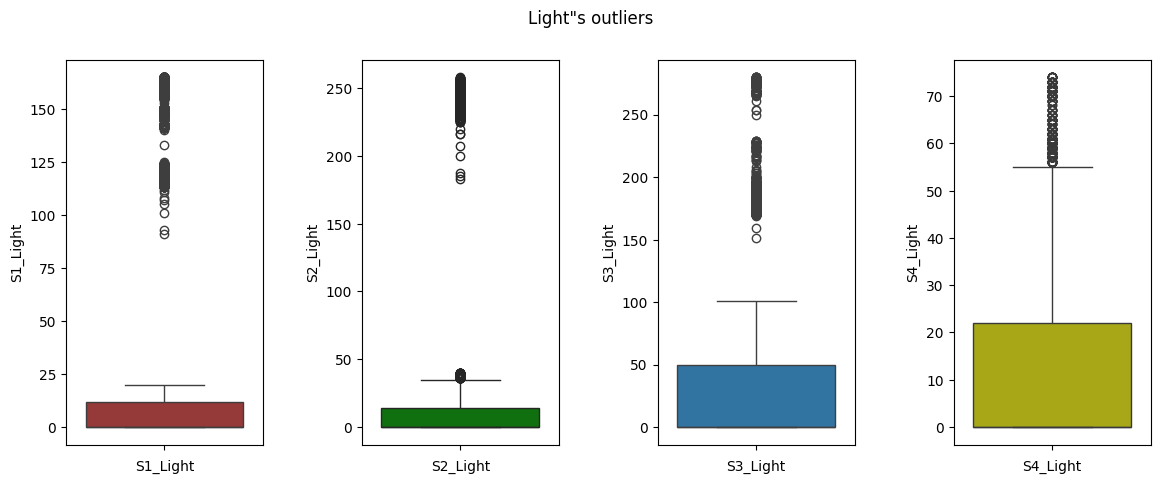

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(14, 5))

plt.subplots_adjust(wspace=0.5)

sns.boxplot(data=df['S1_Light'], ax=ax[0], color='brown')
ax[0].set_xlabel('S1_Light')

sns.boxplot(data=df['S2_Light'], ax=ax[1], color='g')
ax[1].set_xlabel('S2_Light')

sns.boxplot(data=df['S3_Light'], ax=ax[2])
ax[2].set_xlabel('S3_Light')

sns.boxplot(data=df['S4_Light'], ax=ax[3], color='y')
ax[3].set_xlabel('S4_Light')

plt.suptitle('Light"s outliers')

З графіків видно, що більша частина щільності для цих змінних становить близько 0. Це говорить про те, що в цей час немає джерела світла, що логічно, клас 0 складає в порядку 80 % від загальної кількості записів.

Звичайний рівень освітленості в приміщеннях для нормальної діяльності коливається від 100 до 300 люкс, це означає, що значення вище 75-го відсотка є значущими. І вони не виходять за межі нормальних значень освітленості.

тобто ці дані не викиди, а нормальні дані.

Кольорові прямокутники лежать на відмітці 0, а сама медіана дорівнює нулю. Це означає, що більшу частину часу в кімнаті була абсолютна темрява



СО2:

Text(0.5, 0.98, 'CO2"s outliers')

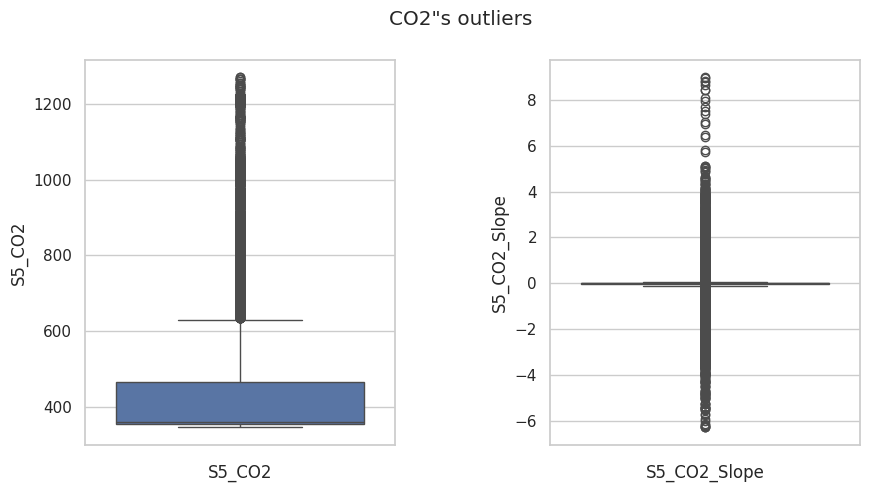

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

plt.subplots_adjust(wspace=0.5)


sns.boxplot(data=df['S5_CO2'], ax=ax[0], color='b')
ax[0].set_xlabel('S5_CO2')

sns.boxplot(data=df['S5_CO2_Slope'], ax=ax[1], color='g')
ax[1].set_xlabel('S5_CO2_Slope')

plt.suptitle('CO2"s outliers')

ЛІВИЙ:
базовий, нормальний рівень CO2 в порожньому або малолюдному приміщенні - 350-460

Коли в кімнаті з'являються люди і довго там перебувають - 600-1270 вони видихають

ПРАВИЙ:
коли в кімнаті нікого немає або ситуація стабільна, рівень CO2 не змінюється (0)
коли люди зайшли - вгору різко, коли вийшли - вниз

Звук:

Text(0.5, 0.98, 'Sound"s outliers')

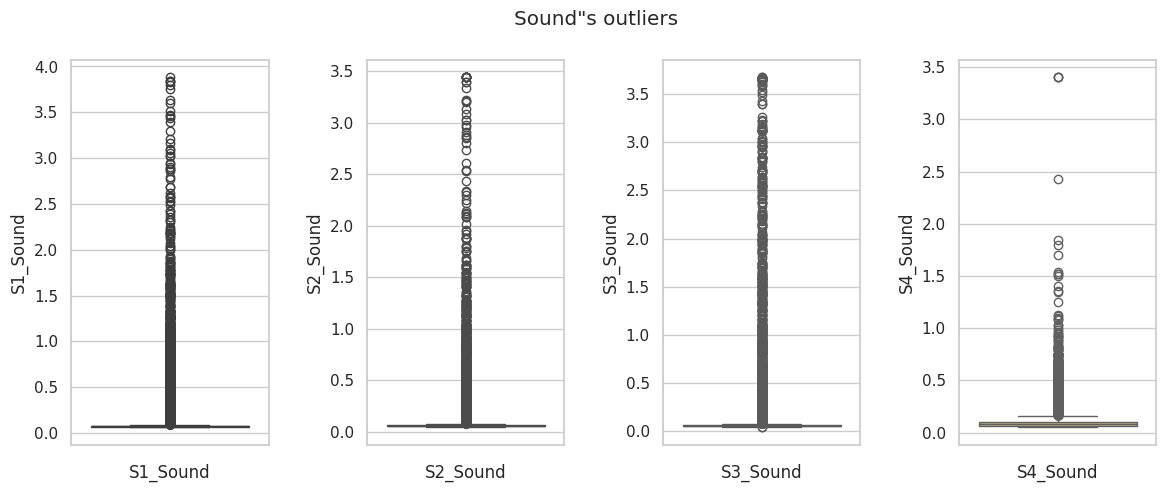

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(14, 5))

plt.subplots_adjust(wspace=0.5)

sns.boxplot(data=df['S1_Sound'], ax=ax[0], color='brown')
ax[0].set_xlabel('S1_Sound')

sns.boxplot(data=df['S2_Sound'], ax=ax[1], color='g')
ax[1].set_xlabel('S2_Sound')

sns.boxplot(data=df['S3_Sound'], ax=ax[2])
ax[2].set_xlabel('S3_Sound')

sns.boxplot(data=df['S4_Sound'], ax=ax[3], color='y')
ax[3].set_xlabel('S4_Sound')

plt.suptitle('Sound"s outliers')

значення від 3 до 4 (на шкалі осі Y) - це стрибки напруги
Коли в кімнаті нікого немає або панує тиша, мікрофон фіксує лише мінімальний фоновий шум або шум напругу (від 0.05 до 0.1В, коробки)
А коли люди говорять, рухаються звукова хвиля коливання підсилює


#5.Аналіз розподілу змінних


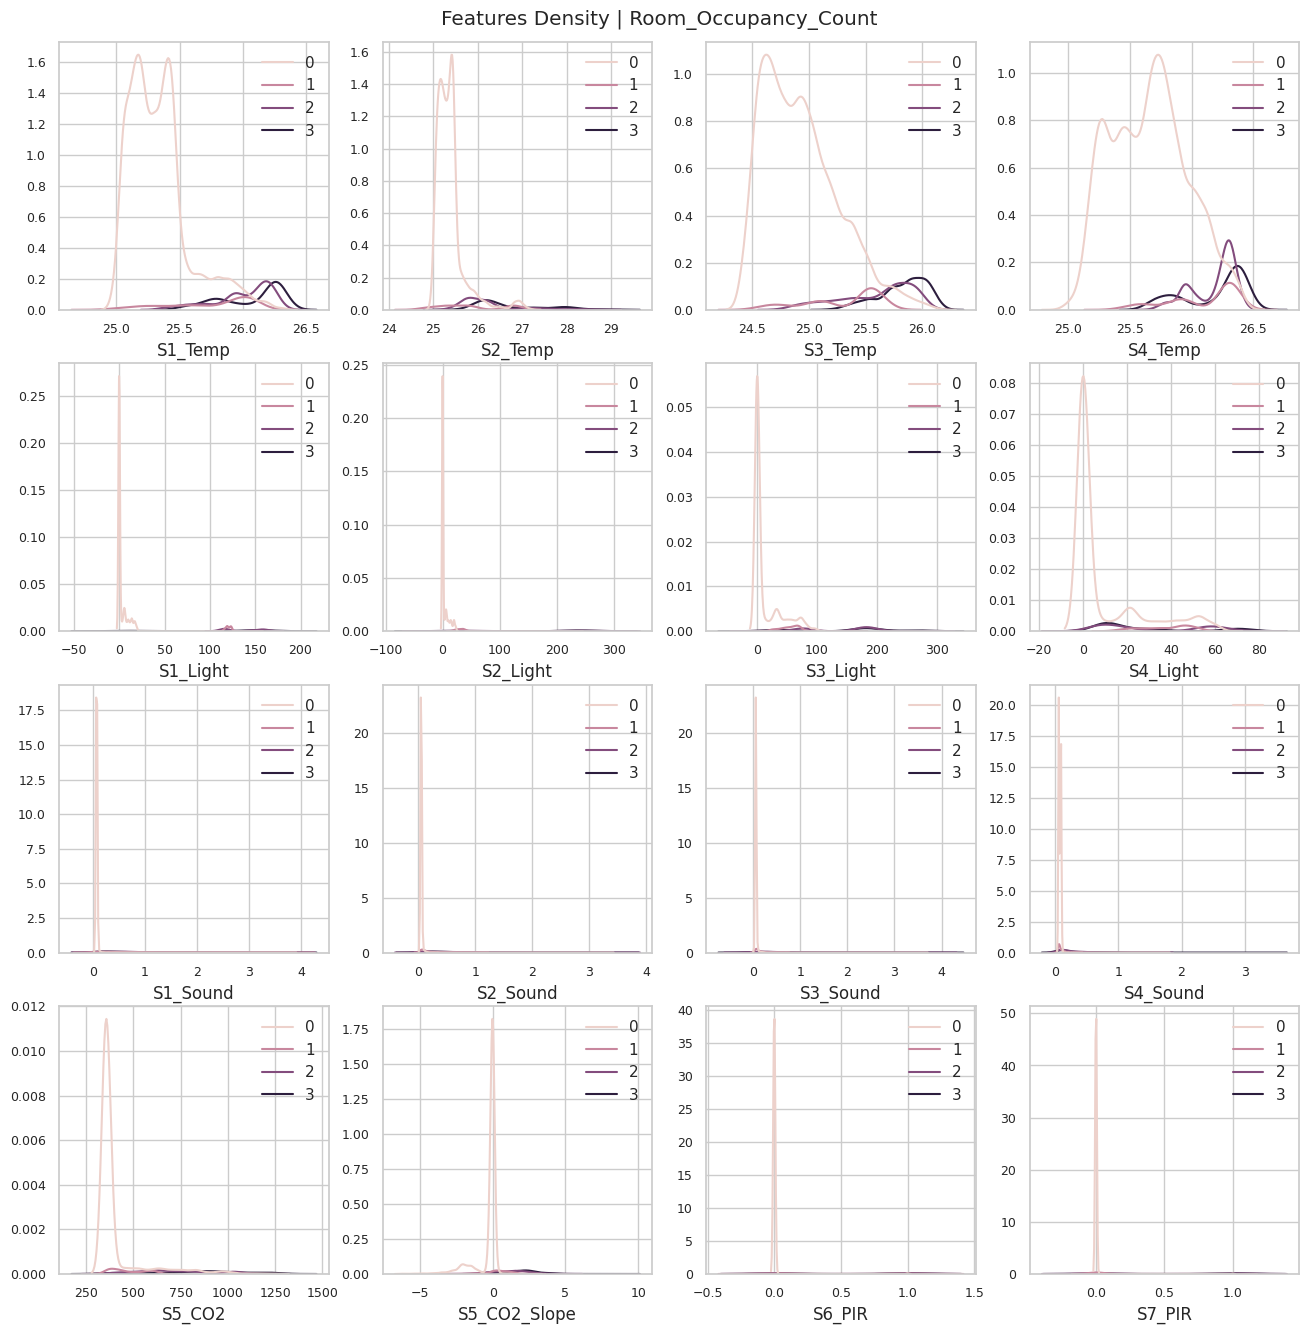

In [ ]:
# Show the correlation between different information (features) and the Room_Occupancy_Count (labels)
columns =  ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light',
       'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound',
       'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']
sns.set_theme(style='whitegrid',rc={'figure.figsize':(16,16)})

fig, axs = plt.subplots(4, 4)
fig.suptitle("Features Density | Room_Occupancy_Count",y=.9)
count = 0 # use for loop through the features
for x in range(4):
    for y in range(4):
        ax = sns.kdeplot(data=df, x=columns[count], hue="Room_Occupancy_Count",ax=axs[x,y])
        ax.set(ylabel=None)
        ax.tick_params(labelsize=9)
        sns.move_legend(ax, "upper right", ncol=1, title=None, frameon=False)
        count += 1

S1_Temp - S4_Temp = 24.5-26.5 - градуси,
У -частота температури появлення

S1_Light - S4_Light - X - освітлення в приміщенні, У -Щільність розподілу ймовірності появи відповідного рівня освітленості

S1_Sound - S4_Sound = X - звуковий тиск у вольтах, У - Щільність розподілу значень напруги фонового шуму або голосової активності

S5_CO2 - Х Концентрація вуглекислого газу в частинах, У - Щільність розподілу рівня CO2 у повітрі

S5_CO2_Slope - Х - Бінарний стан інфрачервоного датчика руху, де 0 - рух відсутній, а 1 - зафіксовано активність.
У - Щільність розподілу динаміки зміни газу.

S6_PIR, S7_PIR - Х - Бінарний стан інфрачервоного датчика руху, де 0 - рух відсутній, а 1 - зафіксовано активність
У - Щільність розподілу бінарних сигналів

#6.Аналіз кореляцій між змінними


In [ ]:
df_notime = df.drop(['Date', 'Time'], axis=1)

Text(0.5, 1, 'Paired correlation between features')

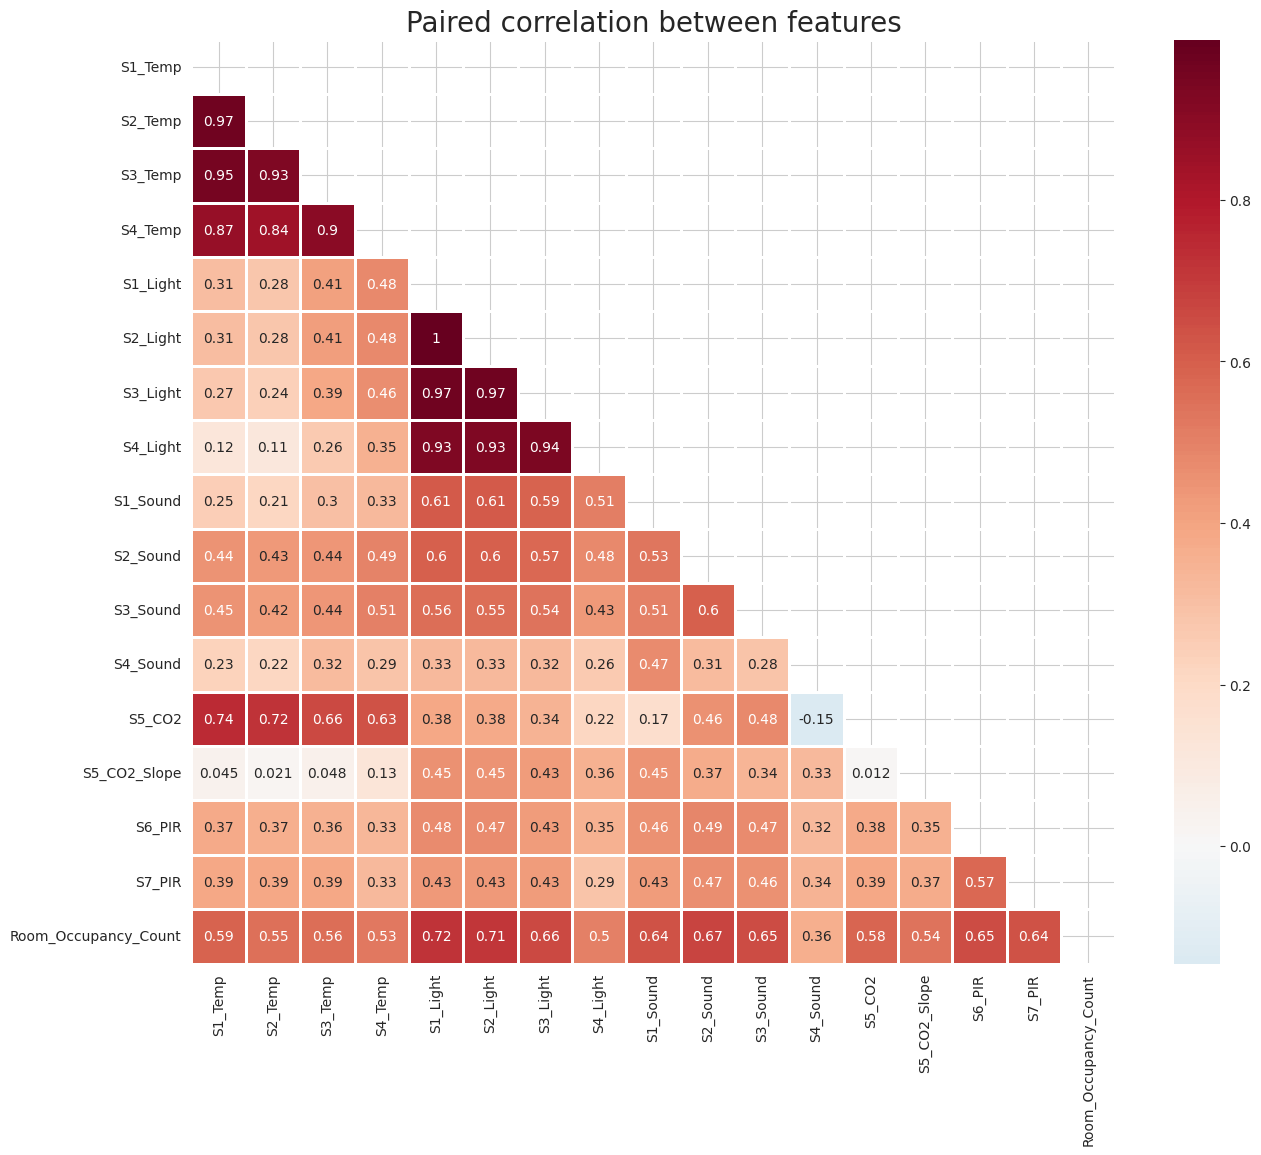

In [ ]:
corr = df_notime.corr(method='spearman') #нелінійні зв'язки
#Спирмен оцінює монотонні зв'язки (наскільки синхронно змінні зростають чи спадають
mask = np.zeros_like(corr, dtype=np.bool_)
mask[np.triu_indices_from(mask)] = True
sns.set_style('whitegrid')
plt.subplots(figsize=(15, 12))
sns.heatmap(corr, annot=True, mask=mask, cmap='RdBu_r',
            linewidths=.9, linecolor='white', fmt='.2g', center=0, square=True)
plt.title('Paired correlation between features', y=1, fontsize=20)


#7.Категоріальний аналіз


In [ ]:
print(pd.DataFrame(df[target].value_counts(normalize=True)*100))
# 81 - понад 81% кімната була порожньою

                      proportion
Room_Occupancy_Count            
0                      81.232106
2                       7.384737
3                       6.851614
1                       4.531543


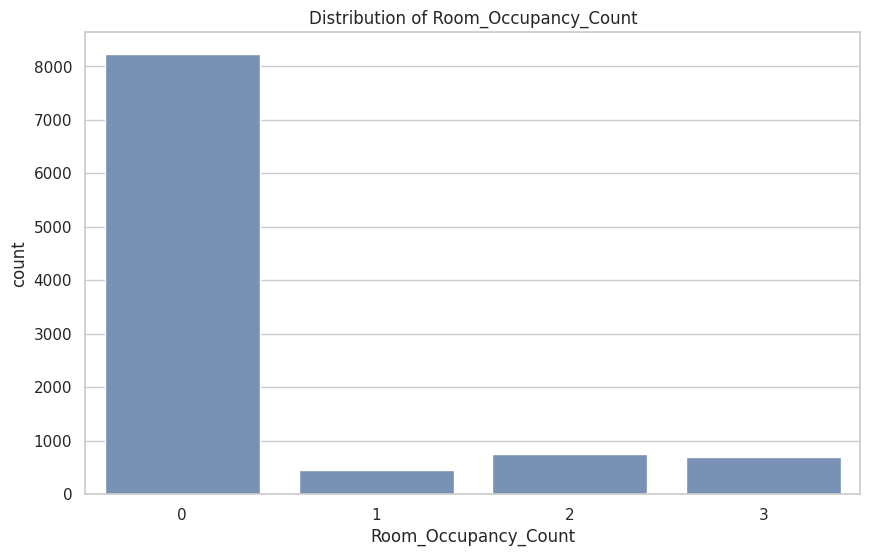

In [ ]:
# check the distribution of labels - Room_Occupancy_Count
sns.set_theme(style='whitegrid',palette='vlag',rc={'figure.figsize':(10,6)})
ax = sns.countplot(x=df.Room_Occupancy_Count)
ax.set(title='Distribution of Room_Occupancy_Count');

<Axes: ylabel='count'>

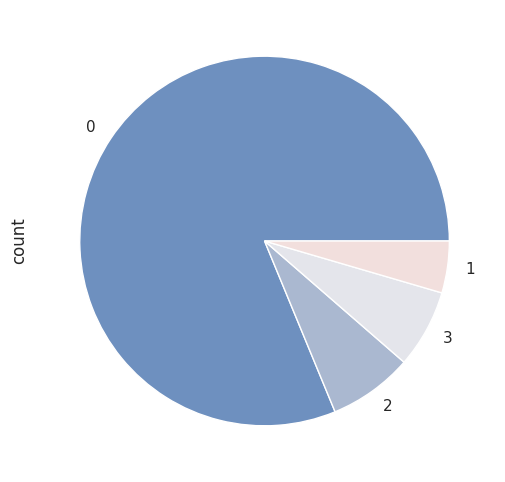

In [ ]:
df['Room_Occupancy_Count'].value_counts().plot(kind='pie')

#8.Аналіз залежності між змінними



In [ ]:
df_notime.columns

Index(['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light',
       'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound',
       'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count'],
      dtype='object')

array([[<Axes: xlabel='S1_Temp', ylabel='S1_Temp'>,
        <Axes: xlabel='S2_Temp', ylabel='S1_Temp'>,
        <Axes: xlabel='S3_Temp', ylabel='S1_Temp'>,
        <Axes: xlabel='S4_Temp', ylabel='S1_Temp'>,
        <Axes: xlabel='S1_Light', ylabel='S1_Temp'>,
        <Axes: xlabel='S2_Light', ylabel='S1_Temp'>,
        <Axes: xlabel='S3_Light', ylabel='S1_Temp'>,
        <Axes: xlabel='S4_Light', ylabel='S1_Temp'>,
        <Axes: xlabel='S1_Sound', ylabel='S1_Temp'>,
        <Axes: xlabel='S2_Sound', ylabel='S1_Temp'>,
        <Axes: xlabel='S3_Sound', ylabel='S1_Temp'>,
        <Axes: xlabel='S4_Sound', ylabel='S1_Temp'>,
        <Axes: xlabel='S5_CO2', ylabel='S1_Temp'>,
        <Axes: xlabel='S5_CO2_Slope', ylabel='S1_Temp'>,
        <Axes: xlabel='S6_PIR', ylabel='S1_Temp'>,
        <Axes: xlabel='S7_PIR', ylabel='S1_Temp'>,
        <Axes: xlabel='Room_Occupancy_Count', ylabel='S1_Temp'>],
       [<Axes: xlabel='S1_Temp', ylabel='S2_Temp'>,
        <Axes: xlabel='S2_Temp', ylabel=

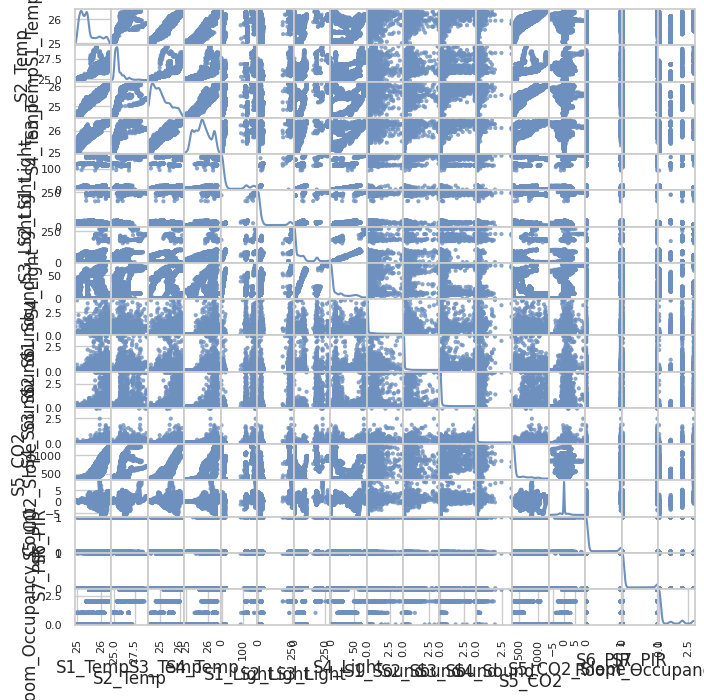

In [ ]:
scatter_matrix(df_notime, alpha=0.8, figsize=(8, 8), diagonal='kde')

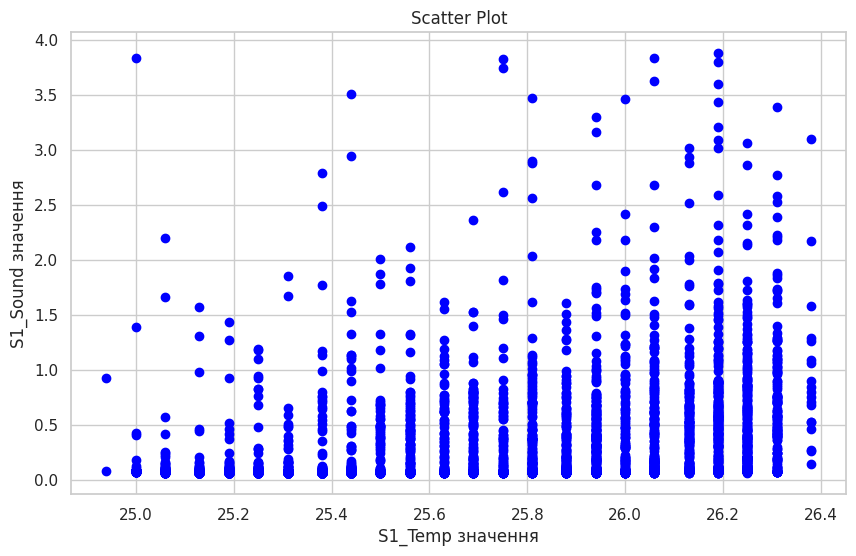

In [ ]:
plt.scatter(df['S1_Temp'], df['S1_Sound'], color='blue')

# Додавання підписів
plt.title('Scatter Plot')
plt.xlabel('S1_Temp значення')
plt.ylabel('S1_Sound значення')

# Показ графіку
plt.show()

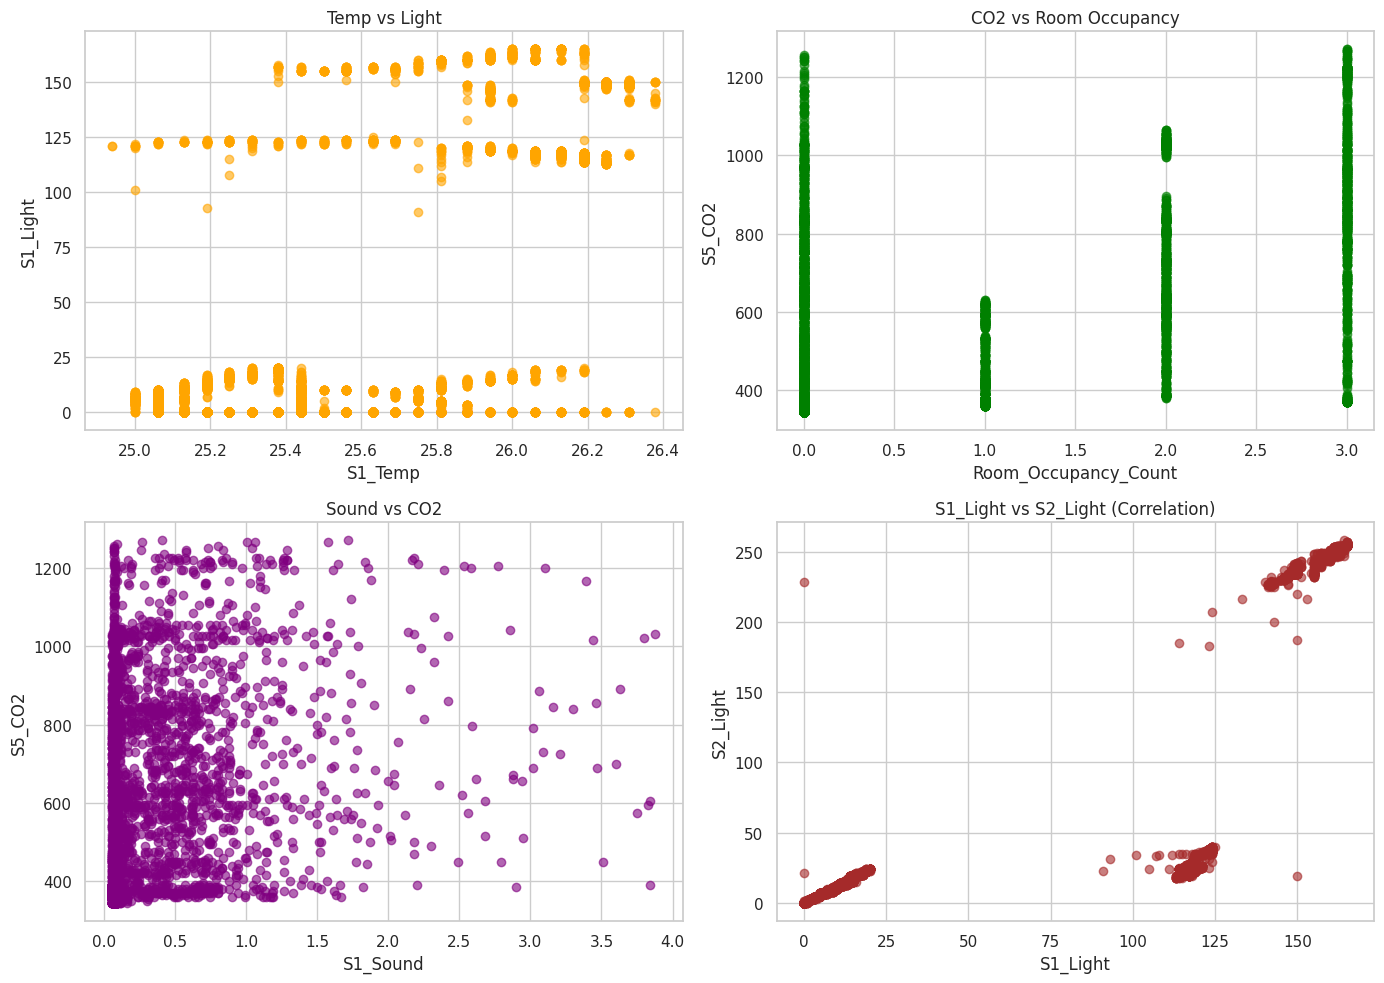

In [ ]:
plt.figure(figsize=(14, 10))

# Графік 1: Зв'язок температури та освітленості (S1_Temp vs S1_Light)
plt.subplot(2, 2, 1)
plt.scatter(df['S1_Temp'], df['S1_Light'], color='orange', alpha=0.6)
plt.title('Temp vs Light')
plt.xlabel('S1_Temp')
plt.ylabel('S1_Light')

# Графік 2: Зв'язок вуглекислого газу та кількості людей (S5_CO2 vs Room_Occupancy_Count)
plt.subplot(2, 2, 2)
plt.scatter(df['Room_Occupancy_Count'], df['S5_CO2'], color='green', alpha=0.6)
plt.title('CO2 vs Room Occupancy')
plt.xlabel('Room_Occupancy_Count')
plt.ylabel('S5_CO2')

# Графік 3: Зв'язок звуку та вуглекислого газу (S1_Sound vs S5_CO2)
plt.subplot(2, 2, 3)
plt.scatter(df['S1_Sound'], df['S5_CO2'], color='purple', alpha=0.6)
plt.title('Sound vs CO2')
plt.xlabel('S1_Sound')
plt.ylabel('S5_CO2')

# Графік 4: Зв'язок двох датчиків світла (S1_Light vs S2_Light)
plt.subplot(2, 2, 4)
plt.scatter(df['S1_Light'], df['S2_Light'], color='brown', alpha=0.6)
plt.title('S1_Light vs S2_Light (Correlation)')
plt.xlabel('S1_Light')
plt.ylabel('S2_Light')

plt.tight_layout()
plt.show()

#9.Агрегація та групування даних

In [ ]:
df['Date'][0]

'2017/12/22'

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y/%m/%d')

In [ ]:
type(df['Date'][0])

pandas._libs.tslibs.timestamps.Timestamp

In [ ]:
# Вибір місяця та року для фільтрації
selected_year = 2017
selected_month = 12

# Фільтрація за обраним місяцем і роком
filtered_df = df[(df['Date'].dt.year == selected_year) & (df['Date'].dt.month == selected_month)]

# Перегляд результату
print(filtered_df)

           Date      Time  S1_Temp  S2_Temp  S3_Temp  S4_Temp  S1_Light  \
0    2017-12-22  10:49:41    24.94    24.75    24.56    25.38       121   
1    2017-12-22  10:50:12    24.94    24.75    24.56    25.44       121   
2    2017-12-22  10:50:42    25.00    24.75    24.50    25.44       121   
3    2017-12-22  10:51:13    25.00    24.75    24.56    25.44       121   
4    2017-12-22  10:51:44    25.00    24.75    24.56    25.44       121   
...         ...       ...      ...      ...      ...      ...       ...   
8079 2017-12-26  09:07:58    25.06    25.06    24.69    25.25         6   
8080 2017-12-26  09:08:29    25.06    25.06    24.69    25.25         6   
8081 2017-12-26  09:08:59    25.06    25.06    24.69    25.25         6   
8082 2017-12-26  09:09:30    25.06    25.06    24.63    25.25         6   
8083 2017-12-26  09:10:01    25.06    25.06    24.69    25.31         6   

      S2_Light  S3_Light  S4_Light  S1_Sound  S2_Sound  S3_Sound  S4_Sound  \
0           34       

In [ ]:
filtered_df

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017-12-22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017-12-22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017-12-22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017-12-22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017-12-22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8079,2017-12-26,09:07:58,25.06,25.06,24.69,25.25,6,7,34,22,0.07,0.05,0.07,0.10,350,0.000000,0,0,0
8080,2017-12-26,09:08:29,25.06,25.06,24.69,25.25,6,7,34,22,0.08,0.05,0.06,0.09,350,0.000000,0,0,0
8081,2017-12-26,09:08:59,25.06,25.06,24.69,25.25,6,7,34,22,0.08,0.05,0.07,0.10,350,0.000000,0,0,0
8082,2017-12-26,09:09:30,25.06,25.06,24.63,25.25,6,7,34,22,0.08,0.05,0.06,0.09,350,0.000000,0,0,0


In [ ]:

#Коли в кімнаті є люди (Room_Occupancy_Count > 0)
occupied_room_df = df[df['Room_Occupancy_Count'] > 0]
print(f"Кількість записів, коли в кімнаті хтось є: {len(occupied_room_df)}")

#коли хоча б один PIR-датчик зафіксував активність == 1
motion_detected_df = df[(df['S6_PIR'] == 1) | (df['S7_PIR'] == 1)]
print(f"Кількість записів із зафіксованим рухом: {len(motion_detected_df)}")

#їбагато людей + високий рівень CO2 > 600 PPM
crowded_and_stuffy = df[(df['Room_Occupancy_Count'] >= 2) & (df['S5_CO2'] > 600)]
print(f"Записи при заповненості >= 2 та високому CO2: {len(crowded_and_stuffy)}")

#середня температура й CO2 для кожної кількості людей
occupancy_grouped = df.groupby('Room_Occupancy_Count')[['S1_Temp', 'S5_CO2', 'S1_Light']].mean()
print("\nСередні показники залежно від кількості людей у кімнаті:")
print(occupancy_grouped)


Кількість записів, коли в кімнаті хтось є: 1901
Кількість записів із зафіксованим рухом: 1198
Записи при заповненості >= 2 та високому CO2: 1085

Середні показники залежно від кількості людей у кімнаті:
                        S1_Temp      S5_CO2    S1_Light
Room_Occupancy_Count                                   
0                     25.336365  404.446403    2.686558
1                     25.741590  470.718954  120.209150
2                     26.003837  713.168449  136.109626
3                     26.066023  851.239193  113.317003


#10.Висновки та гіпотези


Проведений розвідувальний аналіз набору даних Room Occupancy Estimation довів високу якість зібраних показників та виявив значний дисбаланс класів, де понад 81% записів відповідають порожній кімнаті. Дослідження викидів і розподілу підтвердило, що піки освітлення, звуку й рівня CO2 є реальними фізичними процесами, а не похибками датчиків. Аналіз кореляцій за методом Спирмена встановив сильну мультиколінеарність між однаковими сенсорами та водночас виділив ключові індикатори присутності людей - освітленість, вуглекислий газ і дані PIR-руху. Групування даних підтвердило ключову гіпотезу: наявність людей у закритому приміщенні супроводжується закономірним зростанням концентрації CO2 (від 404 PPM до 851 PPM) і зміною мікроклімату, що робить ці ознаки пріоритетними для майбутнього машинного навчання.